# IBM Sales Opportunity Model

**Issue #4: Loading, cleaning, feature definitions, splitting and preprocessing.** No prediction model is trained at this checkpoint.

IBM was selected because its research experiments found more useful win/loss patterns than Maven. This is an academic IBM-data baseline, not proof that the model will work for every business.

We predict eventual **Won (1)** versus **Loss (0)** for one opportunity, using information intended to be available when scoring. A win probability will support sales decisions, not determine which deals must be pursued.

## 1. Imports and constants

Use the already-connected kernel. These imports support table operations, stratified splitting and standard preprocessing; no package installation is needed here. Model-training and SHAP imports will be added in later issues. The output should confirm that the setup cell ran.

In [1]:
from pathlib import Path  # Build file paths without machine-specific directories.

import numpy as np  # Numerical transformations and checks.
import pandas as pd  # CSV loading and table operations.
from IPython.display import display  # Show compact tables in the notebook.

from sklearn.model_selection import train_test_split  # Split rows while preserving class proportions.
from sklearn.compose import ColumnTransformer  # Transform different columns separately.
from sklearn.pipeline import Pipeline  # Apply preparation steps in order.
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

RANDOM_SEED = 42
id_column = "Opportunity Number"
target_column = "Opportunity Result"
amount_column = "Opportunity Amount USD"

# Support running from either the repository root or its notebooks directory.
repository_root = Path.cwd()
if repository_root.name == "notebooks":
    repository_root = repository_root.parent
dataset_path = repository_root / "datasets" / "IBM-sales-opportunity.csv"

print("Issue #4 imports and constants are ready.")

Issue #4 imports and constants are ready.


## 2. Load the dataset

Read the local IBM CSV and inspect only its dimensions, columns and outcomes. `keep_default_na=False` preserves the real category `None`; `na_values=[""]` treats blank fields as missing. No data is downloaded.

Expect 78,025 raw rows and 19 columns. These counts include duplicates, which the next section removes.

In [2]:
raw_df = pd.read_csv(dataset_path, keep_default_na=False, na_values=[""])

print(f"Raw dataset: {len(raw_df):,} rows and {len(raw_df.columns)} columns.")
display(pd.DataFrame({"column": raw_df.columns}))

# Brackets select the outcome column; value_counts counts its labels.
display(raw_df[target_column].value_counts(dropna=False).rename("raw rows").to_frame())
raw_won_prevalence = raw_df[target_column].eq("Won").mean()
print(f"Raw Won prevalence: {raw_won_prevalence:.2%}")

Raw dataset: 78,025 rows and 19 columns.


,column
0,Opportunity Number
1,Supplies Subgroup
2,Supplies Group
3,Region
4,Route To Market
5,Elapsed Days In Sales Stage
6,Opportunity Result
7,Sales Stage Change Count
8,Total Days Identified Through Closing
9,Total Days Identified Through Qualified


,raw rows
Opportunity Result,
Loss,60398
Won,17627


Raw Won prevalence: 22.59%


## 3. Clean records and define the target

Remove exact duplicate rows so the same record is not counted twice.

Some opportunity numbers still have differing details after exact duplicates are removed. The CSV does not explain whether these are line items, updates or separate snapshots; treating them as independent opportunities could duplicate information or leak it across partitions. We therefore conservatively exclude **all** rows for those ambiguous IDs rather than guessing which record to keep.

Map `Won` to `1` and `Loss` to `0`. `.map(...)` translates labels; an unexpected label becomes missing and must fail the check, not become a loss. `assert` stops execution when a required condition is false.

Expect 55 exact duplicates removed, followed by 278 rows from 137 ambiguous IDs, leaving **77,692 unique opportunities**: 17,500 Won and 60,192 Loss. Each retained row represents one opportunity, so the study is limited to these single-record opportunities.

In [3]:
assert raw_df[id_column].notna().all(), "Every record needs an opportunity ID."
deduplicated_df = raw_df.drop_duplicates()

# keep=False marks every remaining row that shares its opportunity ID.
ambiguous_rows = deduplicated_df[id_column].duplicated(keep=False)
ambiguous_id_count = deduplicated_df.loc[ambiguous_rows, id_column].nunique()
# ~ reverses the mask; .loc keeps only unambiguous rows; .copy makes a new table.
cleaned_df = deduplicated_df.loc[~ambiguous_rows].copy()

cleaned_df["target"] = cleaned_df[target_column].map({"Won": 1, "Loss": 0})
assert cleaned_df["target"].notna().all(), "Unexpected or missing outcome label."
cleaned_df["target"] = cleaned_df["target"].astype(int)
assert cleaned_df[id_column].is_unique, "Each retained opportunity must be unique."
assert cleaned_df[amount_column].ge(0).all(), "Amount must be present and nonnegative."

cleaning_counts = pd.Series({
    "Raw rows": len(raw_df),
    "Exact duplicate rows removed": len(raw_df) - len(deduplicated_df),
    "Ambiguous IDs excluded": ambiguous_id_count,
    "Ambiguous rows removed": int(ambiguous_rows.sum()),
    "Retained unique opportunities": len(cleaned_df),
}, name="count")
display(cleaning_counts.to_frame())
display(cleaned_df[target_column].value_counts().rename("opportunities").to_frame())
print(f"Cleaned Won prevalence: {cleaned_df['target'].mean():.2%}")

,count
Raw rows,78025
Exact duplicate rows removed,55
Ambiguous IDs excluded,137
Ambiguous rows removed,278
Retained unique opportunities,77692


,opportunities
Opportunity Result,
Loss,60192
Won,17500


Cleaned Won prevalence: 22.52%


## 4. Define the candidate inputs

A **feature set** is a list of inputs supplied to a model. The four sets answer different research questions:

- **Reference 7:** establish the performance of the richer IBM-specific specification, including product subgroup and region.
- **Portable 5:** check whether product/geography can be removed while retaining similar performance.
- **Lean 3:** keep amount, prior-client revenue and route to check whether the two client-size fields add enough value to justify collecting them.
- **Limited-History 4:** check how useful prediction remains when prior-client revenue is unavailable, using the other four inputs.

Comparing these sets is practical feature selection: test the value of keeping or removing inputs without repeating the entire earlier audit. The table should show exactly which inputs belong to each specification.

History codes `0-4` and client-size codes `1-5` identify groups, not measured money or headcount. Code `4` is not mathematically twice code `2`, so treating them as categories avoids inventing numerical distances. Missing history is different from verified zero, and code `0` alone does not establish a new customer.

IDs, outcomes, later sales durations/ratios, competitor and redundant group/deal-size fields are excluded. Amount and history remain conditional on their availability before the outcome; this CSV cannot verify their timing.

In [4]:
# Each dictionary key names a model specification; its value lists the input columns.
feature_sets = {
    "Reference 7": [
        amount_column, "Revenue From Client Past Two Years", "Route To Market",
        "Client Size By Revenue", "Client Size By Employee Count",
        "Supplies Subgroup", "Region",
    ],
    "Portable 5": [
        amount_column, "Revenue From Client Past Two Years", "Route To Market",
        "Client Size By Revenue", "Client Size By Employee Count",
    ],
    "Lean 3": [
        amount_column, "Revenue From Client Past Two Years", "Route To Market",
    ],
    "Limited-History 4": [
        amount_column, "Route To Market",
        "Client Size By Revenue", "Client Size By Employee Count",
    ],
}

# Selecting a list of columns returns a DataFrame containing only those inputs.
missing_inputs = cleaned_df[feature_sets["Reference 7"]].isna().sum()
assert missing_inputs.eq(0).all(), "Unexpected missing inputs: review before preprocessing."

feature_membership = pd.DataFrame(index=feature_sets["Reference 7"])
for specification, feature_columns in feature_sets.items():
    assert not {id_column, target_column, "target"}.intersection(feature_columns)
    feature_membership[specification] = feature_membership.index.isin(feature_columns)
display(feature_membership.replace({True: "Yes", False: "-"}))

,Reference 7,Portable 5,Lean 3,Limited-History 4
Opportunity Amount USD,Yes,Yes,Yes,Yes
Revenue From Client Past Two Years,Yes,Yes,Yes,-
Route To Market,Yes,Yes,Yes,Yes
Client Size By Revenue,Yes,Yes,-,Yes
Client Size By Employee Count,Yes,Yes,-,Yes
Supplies Subgroup,Yes,-,-,-
Region,Yes,-,-,-


## 5. Separate training, calibration, validation and test

The approximate **50/10/20/20 split is a practical allocation for this relatively large dataset**, not a universal machine-learning rule. It leaves substantial, separate samples for each job:

- **Training (~50%, 38,845 records):** Only these records learn preprocessing parameters and the main predictive patterns. Nearly 39,000 opportunities provide a large training sample while leaving enough data for comparison, probability adjustment and final evaluation.
- **Calibration (~10%, 7,769 records):** Reserve these records to learn an optional adjustment to raw probabilities, not the main predictive patterns. A simple adjustment needs less data than classifier training, so this is a substantial sample for testing it without taking too much from training. Keep it separate from training and validation so the adjustment is learned on records the classifier did not train on and judged on different records.
- **Validation (~20%, 15,539 records):** Compare feature sets and algorithms, then choose calibration and the classification threshold. This large comparison sample helps reduce random variation without touching test results.
- **Test (~20%, 15,539 records):** Reserve these records until features, model, calibration and threshold are fixed. They estimate performance on records not used to fit or choose the approach in this notebook.

**What calibration checks:** among many comparable opportunities given about a 70% chance, do approximately 70% actually win? It checks whether probabilities are realistic across records, not whether one outcome is guaranteed.

**Why stratify?** There are substantially more Loss than Won opportunities. `stratify` keeps approximately the same Won/Loss proportion in each partition, avoiding accidental differences in the class mix caused by random splitting.

**Why fixed seeds?** `random_state` makes the partitions repeatable for the same input data, supporting reproducibility. Seed 42 and the subsequent seeds are simply fixed choices, not mathematically special values.

Cleaning leaves one unique row per opportunity, so `train_test_split` can separate rows directly. Reserve 20% for test, then 25% of the remaining 80% for validation, then one-sixth of the remaining 60% for calibration; integer rounding gives the counts above. The summary checks total row coverage and shows each group's size and win rate.

This changes membership from the earlier research split, but the IBM population has already been inspected. Later results are therefore an internal repeated evaluation, not a completely untouched or external test; absent dates/customer IDs also limit time-based and customer-independent claims. The extra development repeat belongs to Issue #6.

In [5]:
# stratify preserves roughly the same Won/Loss ratio; the seed makes the split repeatable.
development_df, test_df = train_test_split(
    cleaned_df, test_size=0.20, stratify=cleaned_df["target"], random_state=RANDOM_SEED,
)

# A quarter of the remaining 80% is about 20% of the original dataset.
fit_df, validation_df = train_test_split(
    development_df, test_size=0.25, stratify=development_df["target"],
    random_state=RANDOM_SEED + 1,
)

# One sixth of the remaining 60% is about 10%, leaving about 50% for training.
train_df, calibration_df = train_test_split(
    fit_df, test_size=1 / 6, stratify=fit_df["target"], random_state=RANDOM_SEED + 2,
)

In [6]:
partitions = {
    "Training": train_df,
    "Calibration": calibration_df,
    "Validation": validation_df,
    "Test": test_df,
}

# Cleaning already checked unique IDs; confirm that the splits retain every row.
assert sum(len(frame) for frame in partitions.values()) == len(cleaned_df)

partition_rows = []
for partition_name, frame in partitions.items():
    partition_rows.append({
        "partition": partition_name,
        "opportunities": len(frame),
        "share": len(frame) / len(cleaned_df),
        "Won prevalence": frame["target"].mean(),
    })
partition_summary = pd.DataFrame(partition_rows).set_index("partition")
display(partition_summary.round(4))
print("Partition totals match the cleaned dataset.")

,opportunities,share,Won prevalence
partition,,,
Training,38845,0.5,0.2253
Calibration,7769,0.1,0.2253
Validation,15539,0.2,0.2252
Test,15539,0.2,0.2252


Partition totals match the cleaned dataset.


## 6. Prepare model inputs

**Why one-hot encoding?** These algorithms require numerical inputs. One-hot encoding creates 0/1 indicator columns without pretending categories have mathematical distance; IBM history/size codes are group labels, not continuous measurements. `sparse_output=False` returns an ordinary dense numeric array.

**Why `log1p` amount?** Amounts range from small to very large, so compressing the range reduces the influence of extreme numerical sizes; `log(1 + amount)` also safely accepts zero. Earlier IBM research found raw and log amount gave similar predictive performance. We retain the log form as a clean, stable representation, not because larger deals are assumed more likely to win.

**Why standard scaling?** `StandardScaler` puts log amount on a standardized scale using the training mean and standard deviation. Logistic Regression is sensitive to feature scale; trees do not require scaling, but sharing the preprocessing structure keeps comparisons consistent.

**Why fit only on training?** Encoders learn category lists and scalers learn numerical parameters from training rows only. Letting calibration, validation or test records influence these transformations would leak evaluation information into model preparation.

**Why `handle_unknown="ignore"`?** A category absent from training receives all-zero indicators for its field, allowing preprocessing to continue without an encoding failure. This does **not** mean the model understands the new category; the application should later flag it as an input/applicability limitation. That reliability flag is not implemented here.

**Why no imputation?** The audited IBM candidate fields are complete, so no replacement values need to be invented. Unknown prior-client history must not be silently converted to zero: missing information and verified no previous revenue are different business situations, and zero category indicators do not change that distinction.

`ColumnTransformer` applies the appropriate treatment to each column, `Pipeline` keeps log transformation before scaling, and `remainder="drop"` excludes unselected columns. The helper returns a **new, unfitted** preprocessor for each feature list; fit it on training rows and inspect a small transformed batch. Expect four finite numeric batches without fitting on evaluation data.

In [7]:
def build_preprocessor(feature_columns):
    """Return an unfitted ColumnTransformer for a list of approved feature names.

    Amount is log-transformed and scaled. All other selected inputs are
    one-hot encoded as categories; no classifier is fitted here.
    """
    amount_features = [amount_column]
    categorical_features = [column for column in feature_columns if column != amount_column]

    amount_transformer = Pipeline([
        # one-to-one preserves the original column name after log transformation.
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    categorical_encoder = OneHotEncoder(
        handle_unknown="ignore",  # An unseen category gets zeros for this field's indicators.
        sparse_output=False,      # Produce an ordinary numeric array.
    )

    # The output order is encoded categories first, followed by the amount column.
    return ColumnTransformer([
        ("categorical", categorical_encoder, categorical_features),
        ("amount", amount_transformer, amount_features),
    ], remainder="drop")

In [8]:
preprocessors = {}
preprocessing_rows = []

for specification, feature_columns in feature_sets.items():
    training_inputs = train_df[feature_columns]  # Select only this candidate's inputs.
    preprocessor = build_preprocessor(feature_columns)

    # fit learns categories and amount scaling from training rows only.
    preprocessor.fit(training_inputs)
    # transform applies those learned rules to a small batch without refitting.
    training_batch = preprocessor.transform(training_inputs.head(8))
    assert np.isfinite(training_batch).all(), "Preprocessing produced missing or infinite values."

    preprocessors[specification] = preprocessor
    preprocessing_rows.append({
        "specification": specification,
        "original inputs": len(feature_columns),
        "training rows fitted": len(training_inputs),
        "batch rows": training_batch.shape[0],
        "encoded columns": training_batch.shape[1],
    })

preprocessing_summary = pd.DataFrame(preprocessing_rows).set_index("specification")
display(preprocessing_summary)
print("All four training batches transformed successfully; no classifier has been trained.")

,original inputs,training rows fitted,batch rows,encoded columns
specification,,,,
Reference 7,7,38845,8,39
Portable 5,5,38845,8,21
Lean 3,3,38845,8,11
Limited-History 4,4,38845,8,16


All four training batches transformed successfully; no classifier has been trained.


## Issue #4 checkpoint

**Simplified and rerun from the beginning in the connected kernel.**

| Requirement | Result |
|---|---|
| Established cleaning and target | 77,692 unique opportunities; 17,500 Won / 60,192 Loss. Core cleaning assertions retained. |
| Four feature specifications | Reference 7, Portable 5, Lean 3 and Limited-History 4 defined with complete inputs. |
| Sequential stratified splits | 38,845 training / 7,769 calibration / 15,539 validation / 15,539 test; total row coverage checked. Unique IDs were checked during cleaning. |
| Training-only preprocessing | Fitted on 38,845 training rows. All four 8-row batches passed finite-value checks; 39 / 21 / 11 / 16 encoded columns respectively. |
| Unseen categories | `handle_unknown="ignore"` avoids encoding failure; an unseen value gets zero indicators for its field, not learned meaning. Later application reliability must flag it. |
| Readability | Short Markdown explanations, useful syntax comments, direct split calls and one documented `build_preprocessor` helper. |

The grouped-split helper, pairwise overlap loop and unseen-route rejection test have been removed. This update supersedes those choices in the earlier plan. No classifier, calibration adjustment or final test score has been produced.

**Issue #4 establishes the reproducible input pipeline only.** Model training begins in Issue #5 so preprocessing can be reviewed independently before it influences model comparisons.

Issue #4 is ready for review and closure. Suggested commit: `Build IBM preprocessing and feature pipeline`. No commit or GitHub issue action is performed here.

**Next: Issue #5**, the prevalence baseline and Logistic Regression / Random Forest / XGBoost validation comparison. That work has not started. Use fresh model pipelines with `build_preprocessor`, and do not fit transformations on evaluation data.

# Issue #5: Train and Compare Baseline Models

Use the unchanged Issue #4 training and validation partitions for every candidate. This section compares alternatives only: **no test evaluation, calibration, threshold choice, SHAP, fallback decision or final model selection**.

## 7. Baseline Prediction

Before evaluating learned models, establish a simple reference: predict the training Won rate for every validation opportunity, regardless of its inputs. For example, a training win rate near 22.5% produces the same probability near 22.5% for every row; useful models should provide more information than this historical average.

| Metric | Meaning and baseline expectation |
|---|---|
| ROC-AUC | How well actual wins rank above losses: 0.5 is random ranking and 1 is perfect. Constant predictions should give 0.5. An AUC of 0.82 does **not** mean 82% accuracy. |
| Average Precision (AP) | How effectively actual wins appear among higher-scored opportunities, useful because wins are less common. Constant predictions give the validation Won prevalence; AP is not trapezoidal PR area. |
| Brier score | Probability error; lower is better. Predicting 90% for a loss is penalized more than predicting 55%. The baseline supplies the error reference to improve on. |

Import the three planned algorithms and metrics from the existing kernel. No packages are installed here. Classification metrics need a cutoff and belong to Issue #6.

In [9]:
from sklearn.base import clone  # Give each pipeline a fresh copy of an estimator.
from sklearn.linear_model import LogisticRegression  # Simple probabilistic baseline.
from sklearn.ensemble import RandomForestClassifier  # Ensemble of decision trees.
from xgboost import XGBClassifier  # Sequential boosted-tree comparison.
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

print("The three planned algorithms and validation metrics are available.")

The three planned algorithms and validation metrics are available.


### Calculate the reference probabilities

`y_train` and `y_validation` select the known outcome labels from the existing partitions. Since Won is 1 and Loss is 0, `.mean()` equals the fraction of wins. `np.full(...)` repeats that single training rate for every validation row.

The small metric helper accepts true labels and predicted win probabilities and returns the three scores. Reusing it keeps every evaluation consistent; it does not train a model or choose a threshold. Expect a baseline AUC of 0.5 and AP matching validation prevalence.

In [10]:
def probability_metrics(actual_outcomes, win_probabilities):
    """Return three scores for 0/1 outcomes and their predicted Won probabilities."""
    return {
        "ROC-AUC": roc_auc_score(actual_outcomes, win_probabilities),
        "Average Precision": average_precision_score(actual_outcomes, win_probabilities),
        "Brier Score": brier_score_loss(actual_outcomes, win_probabilities),
    }

# y conventionally denotes the target; these are the unchanged Issue #4 labels.
y_train = train_df["target"]
y_validation = validation_df["target"]
# For binary 0/1 labels, the mean is the proportion of Won opportunities.
training_prevalence = y_train.mean()
baseline_probabilities = np.full(len(y_validation), training_prevalence)

baseline_result = {
    "Feature Set": "No features",
    "Model": "Training prevalence",
    **probability_metrics(y_validation, baseline_probabilities),  # Unpack the three scores.
    "Validation Won %": 100 * y_validation.mean(),
}
print(f"Training Won prevalence: {training_prevalence:.4%}")
display(pd.DataFrame([baseline_result]).round(4))

Training Won prevalence: 22.5254%


,Feature Set,Model,ROC-AUC,Average Precision,Brier Score,Validation Won %
0,No features,Training prevalence,0.5,0.2252,0.1745,22.524


## 8. Planned Learning Algorithms

- **Logistic Regression:** learns how inputs combine to increase or decrease estimated win probability. It is a simpler probabilistic baseline against the trees.
- **Random Forest:** builds many trees from different samples and combines their probabilities. It can capture relationships that are not straight-line effects.
- **XGBoost:** builds trees sequentially so later trees improve the current predictions. It provides a second nonlinear comparison, not an assumed winner.

Use **one prespecified configuration per algorithm**, taken from the plan. `n_estimators` is the number of trees; `max_depth` limits tree complexity; `max_iter` gives Logistic Regression time to converge; `learning_rate` controls each boosting step's strength. `random_state=42` makes randomness repeatable and `n_jobs=2` limits tree training to two workers.

The dictionary below holds unfitted model definitions. We keep the natural class balance and do not search for better settings in Issue #5.

In [11]:
models = {
    "Logistic Regression": LogisticRegression(
        C=1.0, solver="lbfgs", max_iter=1500, random_state=RANDOM_SEED,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=12,
        min_samples_leaf=30,  # Keep at least 30 training records in a final tree leaf.
        max_features=0.8,     # Consider 80% of encoded inputs when choosing a split.
        n_jobs=2, random_state=RANDOM_SEED,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=250, max_depth=3, learning_rate=0.05,
        min_child_weight=10,  # Discourage splits with too little statistical support.
        subsample=0.9, colsample_bytree=0.9,  # Sample rows and columns for each tree.
        reg_lambda=5,        # Penalize large tree weights to limit overfitting.
        objective="binary:logistic", eval_metric="logloss", tree_method="hist",
        n_jobs=2, random_state=RANDOM_SEED,
    ),
}
print(f"Defined {len(models)} fixed model configurations; no tuning is performed.")

Defined 3 fixed model configurations; no tuning is performed.


## 9. Train the 12 Candidates

Test each algorithm with each feature specification using exactly the same training and validation opportunities. This separates two questions: **which learning algorithm works well, and which business inputs provide useful information?**

- **Reference 7:** richer IBM-specific comparison.
- **Portable 5:** remove product and geography.
- **Lean 3:** test whether the two client-size fields add value.
- **Limited-History 4:** model without prior-client revenue; retaining a fallback is a later decision.

The outer loop selects a feature list; the inner loop trains each algorithm on that list. `clone(...)` makes an unfitted copy so one combination cannot overwrite another. A `Pipeline` visibly connects the existing preprocessor to the classifier: `.fit(...)` learns from training only, while `.predict_proba(...)` applies the fitted pipeline to validation.

`fitted_models` and `validation_probabilities` keep objects in memory under `(feature set, model name)` keys. This avoids unnecessary retraining when Issue #6 begins; no model files or registry are created. Expect 12 completion messages. **Issue #5 compares alternatives; final selection happens in Issue #6.**

In [12]:
fitted_models = {}
validation_probabilities = {}
validation_rows = [baseline_result]

# The outer loop changes inputs, not the training or validation opportunities.
for feature_set_name, feature_columns in feature_sets.items():
    X_train = train_df[feature_columns]  # X denotes model inputs; y contains outcomes.
    X_validation = validation_df[feature_columns]

    for model_name, model in models.items():
        pipeline = Pipeline([
            ("preprocess", build_preprocessor(feature_columns)),
            ("model", clone(model)),
        ])
        # fit learns both preprocessing parameters and the classifier on training data.
        pipeline.fit(X_train, y_train)
        assert list(pipeline.classes_) == [0, 1], "Check Loss/Won probability column order."
        # predict_proba returns both classes; [:, 1] selects Won for every validation row.
        win_probabilities = pipeline.predict_proba(X_validation)[:, 1]

        candidate_key = (feature_set_name, model_name)
        fitted_models[candidate_key] = pipeline
        validation_probabilities[candidate_key] = win_probabilities
        validation_rows.append({
            "Feature Set": feature_set_name,
            "Model": model_name,
            **probability_metrics(y_validation, win_probabilities),
            "Validation Won %": 100 * y_validation.mean(),
        })
        print(f"Completed: {feature_set_name} / {model_name}")

Completed: Reference 7 / Logistic Regression


Completed: Reference 7 / Random Forest


Completed: Reference 7 / XGBoost


Completed: Portable 5 / Logistic Regression


Completed: Portable 5 / Random Forest


...

Completed: Lean 3 / Random Forest


Completed: Lean 3 / XGBoost


Completed: Limited-History 4 / Logistic Regression


Completed: Limited-History 4 / Random Forest


Completed: Limited-History 4 / XGBoost


## 10. Validation Comparison

Brier matters because the application will display probabilities; ROC-AUC and AP show how well opportunities are ranked. Keep the prevalence baseline first as a reference, then sort learned candidates by **Brier ascending, ROC-AUC descending**.

Expect **13 rows: one baseline and 12 learned combinations**, all evaluated on the same 15,539 validation opportunities. Round only the displayed copy; the stored scores and probabilities retain full precision. The first learned row is not a final model decision.

In [13]:
validation_results = pd.DataFrame(validation_rows)
assert len(validation_results) == 13 and len(fitted_models) == 12
assert len(validation_probabilities) == 12

# Filter out the reference row before sorting the learned candidates.
learned_results = validation_results.loc[
    validation_results["Model"] != "Training prevalence"
].sort_values(["Brier Score", "ROC-AUC"], ascending=[True, False])

comparison_table = pd.concat(
    [pd.DataFrame([baseline_result]), learned_results], ignore_index=True,
)
display(comparison_table.round(5))  # Display rounding does not change stored scores.

,Feature Set,Model,ROC-AUC,Average Precision,Brier Score,Validation Won %
0,No features,Training prevalence,0.50000,0.22524,0.17451,22.52397
1,Reference 7,Random Forest,0.82258,0.60776,0.12820,22.52397
2,Lean 3,Random Forest,0.82173,0.60224,0.12856,22.52397
3,Portable 5,Random Forest,0.81851,0.59872,0.12938,22.52397
4,Reference 7,XGBoost,0.81678,0.60383,0.12998,22.52397
5,Lean 3,XGBoost,0.81672,0.60045,0.13003,22.52397
6,Portable 5,XGBoost,0.81629,0.60004,0.13010,22.52397
7,Limited-History 4,Random Forest,0.77359,0.47239,0.14566,22.52397
8,Reference 7,Logistic Regression,0.72753,0.50124,0.14701,22.52397
9,Portable 5,Logistic Regression,0.72355,0.49540,0.14777,22.52397


### Compare Feature Sets Within Each Algorithm

Arrange the same scores by feature set so the trade-offs are visible before any selection: Reference 7 versus Portable 5 tests product/geography, Portable 5 versus Lean 3 tests the two size fields, and Portable 5 versus Limited-History 4 tests prior-client revenue.

`pivot(...)` rearranges existing results; it does not retrain models or calculate a new performance measure. The second small table shows the lowest-Brier validation row within each algorithm, using the existing ROC-AUC tie-break order. These are inspection summaries only; final selection and the fallback decision remain in Issue #6.

In [14]:
metric_columns = ["ROC-AUC", "Average Precision", "Brier Score"]

# Put the four feature sets in their planned order, with each algorithm beside the others.
feature_comparison = learned_results.pivot(
    index="Feature Set", columns="Model", values=metric_columns,
).reindex(list(feature_sets))
display(feature_comparison.round(5))

# Rows are already sorted by Brier then AUC; keep the first row for each algorithm.
best_by_algorithm = learned_results.drop_duplicates("Model").set_index("Model")
best_by_algorithm = best_by_algorithm.loc[list(models), ["Feature Set"] + metric_columns]
display(best_by_algorithm.round(5))

ROC-AUC                         \
Model             Logistic Regression Random Forest  XGBoost   
Feature Set                                                    
Reference 7                   0.72753       0.82258  0.81678   
Portable 5                    0.72355       0.81851  0.81629   
Lean 3                        0.72592       0.82173  0.81672   
Limited-History 4             0.61300       0.77359  0.76560   

                    Average Precision                         \
Model             Logistic Regression Random Forest  XGBoost   
Feature Set                                                    
Reference 7                   0.50124       0.60776  0.60383   
Portable 5                    0.49540       0.59872  0.60004   
Lean 3                        0.49569       0.60224  0.60045   
Limited-History 4             0.28484       0.47239  0.45882   

                          Brier Score                         
Model             Logistic Regression Random Forest  XGBoost  
Feature Set                                                   
Reference 7                   0.14701       0.12820  0.12998  
Portable 5                    0.14777       0.12938  0.13010  
Lean 3                        0.14778       0.12856  0.13003  
Limited-History 4             0.17100       0.14566  0.14819

,Feature Set,ROC-AUC,Average Precision,Brier Score
Model,,,,
Logistic Regression,Reference 7,0.72753,0.50124,0.14701
Random Forest,Reference 7,0.82258,0.60776,0.12820
XGBoost,Reference 7,0.81678,0.60383,0.12998


## Issue #5 Checkpoint

**The prevalence baseline and all 12 planned learned combinations have executed successfully.** These are validation results from one fixed split, not final-model or test results.

### Observations

- **Baseline:** training Won prevalence is 22.5254%; validation prevalence is 22.5240%. Constant predictions give ROC-AUC **0.50000**, AP **0.22524** and Brier **0.17451**. All 12 learned combinations improve on this reference for these three metrics.
- **Algorithms:** Random Forest has the lowest Brier within each feature specification on this run. The lowest-Brier feature set within each algorithm is Reference 7: Logistic Regression **0.14701**, Random Forest **0.12820**, XGBoost **0.12998**; the tables above give their AUC and AP too.
- **Reference 7 vs Portable 5:** removing product/geography causes small decreases here. For Random Forest, AUC changes from **0.82258 to 0.81851** and Brier from **0.12820 to 0.12938**; XGBoost's corresponding changes are **0.81678 to 0.81629** and **0.12998 to 0.13010**.
- **Portable 5 vs Lean 3:** removing the two size fields improves AUC for all three algorithms. Brier improves for Random Forest (**0.12938 to 0.12856**) and XGBoost (**0.13010 to 0.13003**), while Logistic Regression is nearly unchanged (**0.14777 to 0.14778**). The size fields show little added value in this comparison.
- **Removing history:** Limited-History 4 is worse than Portable 5 on all three metrics for every algorithm. For Random Forest, AUC falls **0.81851 to 0.77359**, AP falls **0.59872 to 0.47239**, and Brier rises **0.12938 to 0.14566**. This shows the cost of removing history, not a decision to retain a fallback.

### Closure Checks

| Requirement | Status |
|---|---|
| Prevalence baseline | Evaluated directly from the training Won rate. |
| Three algorithms across four specifications | All 12 pipelines fitted on the same 38,845 training opportunities. |
| Fair validation comparison | All scored the same 15,539 validation opportunities; preprocessing fitted only on training. |
| Required metrics and tables | ROC-AUC, AP and Brier recorded at full precision; complete comparison and feature-set summaries displayed. |
| Reusable objects | `fitted_models` and `validation_probabilities` retain all 12 candidates in memory; no model files exported. |
| Readability and execution | Visible model definitions, fit/predict steps and short teaching explanations; executed from the beginning through Issue #5. |
| Scope respected | Issue #5 uses training and validation only; no test predictions or evaluation, calibration, threshold selection, classification metrics, SHAP, fallback decision, new split or tuning. |

**Issue #5 is ready for review and closure. No final algorithm or feature set has been selected.** Suggested commit: `Train and compare IBM baseline models`. No commit or GitHub issue action is performed here.

Stop here. Model selection, further validation, calibration, classification cutoff, final internal testing and SHAP remain Issue #6 work.

# Issue #6: Step 1 — Select and prepare the primary model

This section makes the development-data decisions before any final test evaluation or SHAP work. It reuses the Issue #5 fitted pipelines and validation probabilities. A small repeat trains only the Random Forest finalists needed to check the documented simplicity tolerance; it does not rerun all 12 candidates.

Random Forest has the best validation Brier score for every feature set. Lean 3 is compared with Reference 7 because it removes product, region and two client-size fields while retaining amount, prior-client revenue and route.

## 11. Primary-model selection and small stability check

A simpler candidate is acceptable when its ROC-AUC loss is below 0.005 and Brier increase below 0.002 in both development runs. The code below keeps the original test partition out of the work: it re-splits only the existing development records, then fits the three Random Forest specifications needed for this decision.

In [15]:
# Re-split development data only; test_df is never supplied to fit or predict here.
repeat_fit_df, repeat_validation_df = train_test_split(
    development_df, test_size=0.25, stratify=development_df["target"], random_state=53,
)
repeat_train_df, _ = train_test_split(
    repeat_fit_df, test_size=1 / 6, stratify=repeat_fit_df["target"], random_state=54,
)

repeat_rows = []
for specification in ["Reference 7", "Lean 3", "Limited-History 4"]:
    columns = feature_sets[specification]
    repeat_pipeline = Pipeline([
        ("preprocess", build_preprocessor(columns)),
        ("model", clone(models["Random Forest"])),
    ])
    # fit learns this repeat's preprocessing and classifier from training rows only.
    repeat_pipeline.fit(repeat_train_df[columns], repeat_train_df["target"])
    repeat_probabilities = repeat_pipeline.predict_proba(repeat_validation_df[columns])[:, 1]
    repeat_rows.append({"Feature Set": specification, **probability_metrics(
        repeat_validation_df["target"], repeat_probabilities
    )})

repeat_results = pd.DataFrame(repeat_rows).set_index("Feature Set")
selection_comparison = pd.DataFrame([
    {"run": "Original", "Feature Set": "Reference 7", **probability_metrics(y_validation, validation_probabilities[("Reference 7", "Random Forest")])},
    {"run": "Original", "Feature Set": "Lean 3", **probability_metrics(y_validation, validation_probabilities[("Lean 3", "Random Forest")])},
    {"run": "Repeat", "Feature Set": "Reference 7", **repeat_results.loc["Reference 7"].to_dict()},
    {"run": "Repeat", "Feature Set": "Lean 3", **repeat_results.loc["Lean 3"].to_dict()},
])
display(selection_comparison.round(5))

# Lean 3 remains inside both practical tolerances, so prefer its smaller input contract.
primary_key = ("Lean 3", "Random Forest")
primary_pipeline = fitted_models[primary_key]
raw_validation_probabilities = validation_probabilities[primary_key]
print("Selected primary model: Random Forest with Lean 3.")

,run,Feature Set,ROC-AUC,Average Precision,Brier Score
0,Original,Reference 7,0.82258,0.60776,0.12820
1,Original,Lean 3,0.82173,0.60224,0.12856
2,Repeat,Reference 7,0.82272,0.61487,0.12702
3,Repeat,Lean 3,0.82222,0.60862,0.12756


Selected primary model: Random Forest with Lean 3.


## 12. Limited-history fallback

The comparison uses the same validation opportunities. The history-aware primary should abstain when history is genuinely unknown; it must not treat missing history as zero. Limited-History 4 is retained only as a conditional raw-probability fallback because it improves on prevalence in both development runs, while its loss relative to the primary is recorded below. IBM history code `0` remains a known category, not evidence of a new customer.

In [16]:
fallback_key = ("Limited-History 4", "Random Forest")
fallback_validation_probabilities = validation_probabilities[fallback_key]
primary_metrics = probability_metrics(y_validation, raw_validation_probabilities)
fallback_metrics = probability_metrics(y_validation, fallback_validation_probabilities)
fallback_comparison = pd.DataFrame([
    {"Model": "Lean 3 primary", **primary_metrics},
    {"Model": "Limited-History 4 fallback", **fallback_metrics},
])
for metric in ["ROC-AUC", "Average Precision", "Brier Score"]:
    fallback_comparison[f"Difference from primary ({metric})"] = (
        fallback_comparison[metric] - primary_metrics[metric]
    )
display(fallback_comparison.round(5))

,Model,ROC-AUC,Average Precision,Brier Score,Difference from primary (ROC-AUC),Difference from primary (Average Precision),Difference from primary (Brier Score)
0,Lean 3 primary,0.82173,0.60224,0.12856,0.00000,0.00000,0.0000
1,Limited-History 4 fallback,0.77359,0.47239,0.14566,-0.04814,-0.12985,0.0171


## 13. Probability calibration

Calibration asks whether predicted probabilities match observed win rates across groups. The sigmoid mapping is fitted on `calibration_df`, never validation or test data, then judged by validation Brier and ten-bin reliability. `np.clip` keeps probabilities away from exactly 0 or 1 before `log` converts them to log-odds; `.reshape(-1, 1)` supplies Logistic Regression with its required two-dimensional single-feature input.

In [17]:
from sklearn.metrics import precision_recall_curve

primary_columns = feature_sets["Lean 3"]
calibration_probabilities = primary_pipeline.predict_proba(calibration_df[primary_columns])[:, 1]
epsilon = 1e-6

def probability_log_odds(probabilities):
    """Convert clipped probabilities to one numeric log-odds feature for sigmoid calibration."""
    clipped = np.clip(probabilities, epsilon, 1 - epsilon)
    return np.log(clipped / (1 - clipped))

calibrator = LogisticRegression(
    C=1e6, solver="lbfgs", max_iter=1000, random_state=RANDOM_SEED,
)
# The calibrator learns only the relationship between calibration probabilities and outcomes.
calibrator.fit(probability_log_odds(calibration_probabilities).reshape(-1, 1), calibration_df["target"])
sigmoid_validation_probabilities = calibrator.predict_proba(
    probability_log_odds(raw_validation_probabilities).reshape(-1, 1)
)[:, 1]

calibration_comparison = pd.DataFrame([
    {"Probability version": "Raw", **probability_metrics(y_validation, raw_validation_probabilities)},
    {"Probability version": "Sigmoid", **probability_metrics(y_validation, sigmoid_validation_probabilities)},
])
display(calibration_comparison.round(5))

reliability_rows = []
for label, probabilities in [("Raw", raw_validation_probabilities), ("Sigmoid", sigmoid_validation_probabilities)]:
    reliability_frame = pd.DataFrame({"actual Won": y_validation.to_numpy(), "probability": probabilities})
    reliability_frame["bin"] = pd.cut(reliability_frame["probability"], bins=np.linspace(0, 1, 11), include_lowest=True)
    reliability = reliability_frame.groupby("bin", observed=False).agg(
        count=("actual Won", "size"), mean_prediction=("probability", "mean"), observed_won_rate=("actual Won", "mean"),
    ).reset_index()
    reliability.insert(0, "Probability version", label)
    reliability_rows.append(reliability)
reliability_table = pd.concat(reliability_rows, ignore_index=True)
display(reliability_table.round(4))

# Keep raw probabilities unless sigmoid improves validation probability quality by a meaningful amount.
selected_validation_probabilities = raw_validation_probabilities
calibration_decision = "Raw retained: sigmoid Brier improvement is too small to justify extra serving complexity."
print(calibration_decision)

,Probability version,ROC-AUC,Average Precision,Brier Score
0,Raw,0.82173,0.60224,0.12856
1,Sigmoid,0.82173,0.60224,0.12854


,Probability version,bin,count,mean_prediction,observed_won_rate
0,Raw,"(-0.001, 0.1]",5772,0.0591,0.0537
1,Raw,"(0.1, 0.2]",3963,0.1390,0.1340
2,Raw,"(0.2, 0.3]",1603,0.2431,0.2695
3,Raw,"(0.3, 0.4]",1378,0.3447,0.3723
4,Raw,"(0.4, 0.5]",951,0.4415,0.4721
5,Raw,"(0.5, 0.6]",700,0.5449,0.5314
6,Raw,"(0.6, 0.7]",273,0.6468,0.6740
7,Raw,"(0.7, 0.8]",389,0.7530,0.7352
8,Raw,"(0.8, 0.9]",397,0.8429,0.8035
9,Raw,"(0.9, 1.0]",113,0.9260,0.9204


Raw retained: sigmoid Brier improvement is too small to justify extra serving complexity.


## 14. Validation-selected classification threshold

A threshold converts a probability into a Won/Loss class for academic classification metrics. We maximize validation F1 and choose the higher threshold if F1 ties. This cutoff is not an application prioritization rule: sales attention still depends on opportunity value, urgency, reliability and human judgement.

In [18]:
precision, recall, thresholds = precision_recall_curve(y_validation, selected_validation_probabilities)
# precision_recall_curve has one final precision/recall pair without a matching threshold.
f1_values = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1])
f1_values = np.nan_to_num(f1_values, nan=0.0)
best_f1 = f1_values.max()
classification_threshold = thresholds[f1_values == best_f1].max()
print(f"Validation F1 threshold: {classification_threshold:.5f}; F1: {best_f1:.5f}")

Validation F1 threshold: 0.22271; F1: 0.58492


## Step 1 decision record

**Primary model:** Random Forest with **Lean 3** predictors: `Opportunity Amount USD`, `Revenue From Client Past Two Years`, and `Route To Market`. On the original validation split it achieves ROC-AUC **0.82173**, AP **0.60224**, and Brier **0.12856**. Reference 7 is only 0.00085 higher in ROC-AUC and 0.00036 lower in Brier; the repeat differences (0.00051 ROC-AUC and 0.00054 Brier) are also inside the documented 0.005/0.002 tolerances. Lean 3 therefore removes four inputs without a material probability-quality loss.

**Limited-history fallback:** retain Random Forest Limited-History 4 only when prior-client history is genuinely unavailable. Its original validation metrics are ROC-AUC **0.77359**, AP **0.47239**, and Brier **0.14566** (a Brier increase of 0.01710 versus the primary), but it improves on the prevalence baseline in both development runs. It is not a new-customer model, and it must not replace unknown history with IBM code `0`.

**Calibration:** raw probability Brier is **0.12856**; sigmoid calibration reaches **0.12854**, an improvement of only 0.00003. Retain raw probabilities because that marginal change does not justify another runtime step.

**Classification threshold:** use **0.22271** (validation F1 **0.58492**) for later academic classification reporting only. It is separate from business prioritization.

The test partition remains untouched: this step does not predict, evaluate, tune against, or inspect test outcomes. Remaining work—final internal test evaluation and SHAP—requires separate authorization. IBM timing/code semantics and cross-organization transfer remain unverified.

## 15. Final internal test evaluation

The model choices are now frozen: Lean 3 Random Forest, raw probabilities, the 0.22271 validation threshold, and the conditional Limited-History 4 fallback. The held-out test partition is scored once for reporting only; its results will not change any choice. Rows are actual outcomes and columns are predicted outcomes, ordered `[Loss, Won]`. A false positive is a Lost opportunity classified as Won; a false negative is a Won opportunity classified as Loss.

In [19]:
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

# predict_proba returns Loss and Won columns; [:, 1] selects the Won probability.
test_probabilities = primary_pipeline.predict_proba(test_df[primary_columns])[:, 1]
assert np.logical_and(test_probabilities >= 0, test_probabilities <= 1).all()

test_metrics = {
    **probability_metrics(test_df["target"], test_probabilities),
    "Test Won prevalence": test_df["target"].mean(),
    "Training prevalence Brier": brier_score_loss(test_df["target"], np.full(len(test_df), training_prevalence)),
}
test_predictions = (test_probabilities >= classification_threshold).astype(int)
test_metrics.update({
    "Precision at validation threshold": precision_score(test_df["target"], test_predictions),
    "Recall at validation threshold": recall_score(test_df["target"], test_predictions),
    "F1 at validation threshold": f1_score(test_df["target"], test_predictions),
    "Minimum probability": test_probabilities.min(),
    "Maximum probability": test_probabilities.max(),
})
display(pd.DataFrame([test_metrics]).round(5))

test_confusion_matrix = confusion_matrix(test_df["target"], test_predictions, labels=[0, 1])
display(pd.DataFrame(test_confusion_matrix, index=["Actual Loss", "Actual Won"], columns=["Predicted Loss", "Predicted Won"]))
display(pd.Series(test_probabilities).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).to_frame("Won probability").round(5))

,ROC-AUC,Average Precision,Brier Score,Test Won prevalence,Training prevalence Brier,Precision at validation threshold,Recall at validation threshold,F1 at validation threshold,Minimum probability,Maximum probability
0,0.81619,0.59685,0.12974,0.22524,0.17451,0.48279,0.72543,0.57975,0.00282,0.95118


,Predicted Loss,Predicted Won
Actual Loss,9319,2720
Actual Won,961,2539


,Won probability
count,15539.00000
mean,0.22440
std,0.21333
min,0.00282
5%,0.02159
25%,0.07403
50%,0.13205
75%,0.32027
95%,0.73264
max,0.95118


## Test probability reliability

Calibration checks whether predicted probabilities correspond to actual outcomes. For example, opportunities assigned approximately 70% should win about 70% of the time across enough comparable records. ROC-AUC measures ranking, so it cannot establish calibration by itself. Sparse bins are reported rather than treated as precise evidence.

In [20]:
test_reliability_frame = pd.DataFrame({"actual Won": test_df["target"].to_numpy(), "probability": test_probabilities})
test_reliability_frame["Probability range"] = pd.cut(
    test_reliability_frame["probability"], bins=np.linspace(0, 1, 11), include_lowest=True,
)
test_reliability = test_reliability_frame.groupby("Probability range", observed=False).agg(
    opportunities=("actual Won", "size"),
    average_prediction=("probability", "mean"),
    actual_won_rate=("actual Won", "mean"),
).reset_index()
test_reliability["prediction_minus_observed"] = (
    test_reliability["average_prediction"] - test_reliability["actual_won_rate"]
)
test_reliability["support note"] = np.where(test_reliability["opportunities"] < 30, "Sparse: interpret cautiously", "")
display(test_reliability.round(4))

,Probability range,opportunities,average_prediction,actual_won_rate,prediction_minus_observed,support note
0,"(-0.001, 0.1]",5796,0.0590,0.0583,0.0007,
1,"(0.1, 0.2]",3911,0.1396,0.1314,0.0081,
2,"(0.2, 0.3]",1574,0.2450,0.2922,-0.0472,
3,"(0.3, 0.4]",1401,0.3448,0.3433,0.0014,
4,"(0.4, 0.5]",971,0.4404,0.4521,-0.0118,
5,"(0.5, 0.6]",695,0.5482,0.5367,0.0115,
6,"(0.6, 0.7]",306,0.6489,0.6078,0.0411,
7,"(0.7, 0.8]",383,0.7559,0.7389,0.0170,
8,"(0.8, 0.9]",386,0.8458,0.8264,0.0194,
9,"(0.9, 1.0]",116,0.9250,0.9224,0.0026,


## Limited-history fallback internal test

This frozen Random Forest uses amount, route, and the two client-size categories without prior-client revenue. It is evaluated on the same resolved IBM test opportunities for an internal comparison. This does not validate new-customer performance or naturally incomplete history, and verified zero history remains different from unavailable history.

In [21]:
fallback_columns = feature_sets["Limited-History 4"]
fallback_pipeline = fitted_models[fallback_key]
fallback_test_probabilities = fallback_pipeline.predict_proba(test_df[fallback_columns])[:, 1]
assert np.logical_and(fallback_test_probabilities >= 0, fallback_test_probabilities <= 1).all()

fallback_test_metrics = {
    **probability_metrics(test_df["target"], fallback_test_probabilities),
    "Minimum probability": fallback_test_probabilities.min(),
    "Maximum probability": fallback_test_probabilities.max(),
}
display(pd.DataFrame([fallback_test_metrics]).round(5))

fallback_reliability = pd.DataFrame({"actual Won": test_df["target"].to_numpy(), "probability": fallback_test_probabilities})
fallback_reliability["Probability range"] = pd.cut(fallback_reliability["probability"], bins=np.linspace(0, 1, 11), include_lowest=True)
fallback_reliability = fallback_reliability.groupby("Probability range", observed=False).agg(
    opportunities=("actual Won", "size"), average_prediction=("probability", "mean"), actual_won_rate=("actual Won", "mean"),
).reset_index()
fallback_reliability["prediction_minus_observed"] = fallback_reliability["average_prediction"] - fallback_reliability["actual_won_rate"]
display(fallback_reliability.round(4))

,ROC-AUC,Average Precision,Brier Score,Minimum probability,Maximum probability
0,0.76504,0.46856,0.14686,0.00307,0.74629


,Probability range,opportunities,average_prediction,actual_won_rate,prediction_minus_observed
0,"(-0.001, 0.1]",3246,0.0564,0.0502,0.0062
1,"(0.1, 0.2]",5442,0.1441,0.1316,0.0125
2,"(0.2, 0.3]",2579,0.2460,0.2489,-0.0029
3,"(0.3, 0.4]",1710,0.3471,0.3865,-0.0394
4,"(0.4, 0.5]",1345,0.4492,0.4513,-0.0021
5,"(0.5, 0.6]",926,0.5419,0.5778,-0.0359
6,"(0.6, 0.7]",272,0.6376,0.6029,0.0347
7,"(0.7, 0.8]",19,0.7348,0.6316,0.1033
8,"(0.8, 0.9]",0,NaN,NaN,NaN
9,"(0.9, 1.0]",0,NaN,NaN,NaN


## 16. SHAP explanations for the selected Lean 3 model

SHAP explains how the trained model produces predictions; it does not prove that changing a feature will cause an opportunity to be Won. We explain the Random Forest's Won (`1`) probability output on a fixed 200-row validation sample. One-hot category contributions are added back to the three original business fields before interpreting them.

/home/emmanuel/.venvs/opportunity-scoring/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
 92%|==================  | 366/400 [00:11<00:01]       

,mean absolute SHAP value
Opportunity Amount USD,0.10163
Revenue From Client Past Two Years,0.07865
Route To Market,0.02714


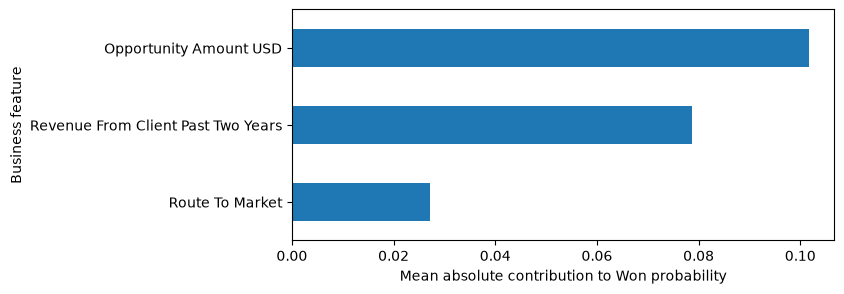

In [22]:
import matplotlib.pyplot as plt
import shap

shap_sample = validation_df[primary_columns].sample(n=200, random_state=142)
shap_background = train_df[primary_columns].sample(n=100, random_state=142)
preprocessor = primary_pipeline.named_steps["preprocess"]
forest_model = primary_pipeline.named_steps["model"]
shap_sample_transformed = preprocessor.transform(shap_sample)
shap_background_transformed = preprocessor.transform(shap_background)
encoded_feature_names = preprocessor.get_feature_names_out()

# Interventional probability output makes the additivity check comparable to predict_proba.
explainer = shap.TreeExplainer(
    forest_model, data=shap_background_transformed, feature_perturbation="interventional", model_output="probability",
)
shap_output = explainer(shap_sample_transformed)
won_shap_values = shap_output.values[:, :, 1] if shap_output.values.ndim == 3 else shap_output.values
won_base_values = shap_output.base_values[:, 1] if np.ndim(shap_output.base_values) == 2 else shap_output.base_values
shap_sample_probabilities = primary_pipeline.predict_proba(shap_sample)[:, 1]
assert np.allclose(won_base_values + won_shap_values.sum(axis=1), shap_sample_probabilities, atol=1e-6)

feature_owner = []
for encoded_name in encoded_feature_names:
    feature_owner.append(next(column for column in primary_columns if encoded_name.endswith(column) or encoded_name.startswith(f"categorical__{column}_")))
business_shap = pd.DataFrame({
    column: won_shap_values[:, np.array(feature_owner) == column].sum(axis=1)
    for column in primary_columns
})
global_shap_importance = business_shap.abs().mean().sort_values(ascending=False).rename("mean absolute SHAP value").to_frame()
display(global_shap_importance.round(5))

ax = global_shap_importance.sort_values("mean absolute SHAP value").plot.barh(legend=False, figsize=(7, 3))
ax.set_xlabel("Mean absolute contribution to Won probability")
ax.set_ylabel("Business feature")
plt.show()

### SHAP direction and one local explanation

The chart below uses the original opportunity amount on a logarithmic horizontal scale and its aggregated SHAP contribution to the Won probability. Positive values raise the probability relative to SHAP's reference prediction; negative values lower it. The local example is the sampled validation opportunity closest to the sample's median predicted probability, chosen without its outcome.

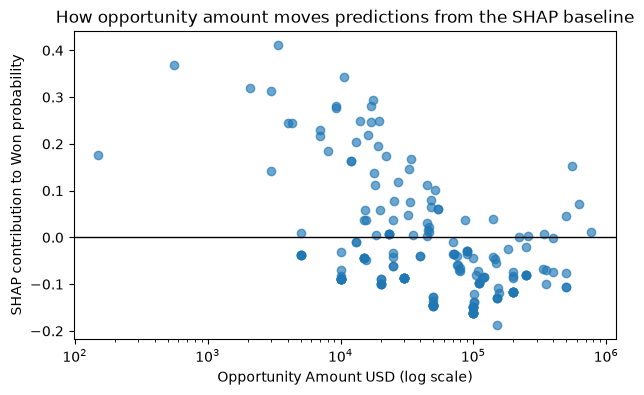

,Opportunity Amount USD,Revenue From Client Past Two Years,Route To Market
74468,25000,0,Fields Sales


,contribution to Won probability
Route To Market,-0.00069
Opportunity Amount USD,-0.04217
Revenue From Client Past Two Years,-0.05775


SHAP reference probability: 0.23198
Model Won probability: 0.13137
Positive contributions raise this probability; negative contributions lower it relative to the SHAP reference.


In [23]:
plt.figure(figsize=(7, 4))
plt.scatter(shap_sample[amount_column], business_shap[amount_column], alpha=0.65)
plt.xscale("log")
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Opportunity Amount USD (log scale)")
plt.ylabel("SHAP contribution to Won probability")
plt.title("How opportunity amount moves predictions from the SHAP baseline")
plt.show()

local_position = np.abs(shap_sample_probabilities - np.median(shap_sample_probabilities)).argmin()
local_record = shap_sample.iloc[[local_position]]
local_contributions = business_shap.iloc[local_position].sort_values(ascending=False).rename("contribution to Won probability").to_frame()
local_base_value = won_base_values[local_position]
local_probability = shap_sample_probabilities[local_position]
display(local_record)
display(local_contributions.round(5))
print(f"SHAP reference probability: {local_base_value:.5f}")
print(f"Model Won probability: {local_probability:.5f}")
print("Positive contributions raise this probability; negative contributions lower it relative to the SHAP reference.")

## Final Model Decision

The selected primary algorithm is **Random Forest with Lean 3**: Opportunity Amount USD, Revenue From Client Past Two Years, and Route To Market. Lean 3 was preferred over Reference 7 and Portable 5 because it removes product, geography and client-size inputs while staying within the documented validation/stability tolerances. Validation results are ROC-AUC 0.82173, AP 0.60224 and Brier 0.12856.

The final internal test reports ROC-AUC **0.81619**, AP **0.59685** and Brier **0.12974**, compared with a training-prevalence Brier of 0.17451. At the frozen 0.22271 threshold, precision is **0.48279**, recall **0.72543** and F1 **0.57975**. Raw probabilities are retained because sigmoid calibration did not improve validation Brier enough to justify another step. The threshold is for academic classification reporting only, not commercial opportunity prioritization.

Random Forest Limited-History 4 is retained only when prior-client revenue is genuinely unavailable; its internal-test ROC-AUC/AP/Brier are **0.76504 / 0.46856 / 0.14686**. It is not a new-customer model; verified zero history and unavailable history remain distinct. The SHAP outputs show global importance (amount, prior-client revenue, then route), an amount-direction view, and a representative local explanation.

The prediction is the **estimated probability that a sales opportunity will eventually be Won, based on the selected IBM-trained model and its approved input representation.** SHAP explains trained-model behaviour, not causal effects. This final test is a repeated internal evaluation on an already-inspected holdout, not external validation. IBM prediction-time feature availability, code meanings and cross-organization transfer remain unverified.